# Classifying Twitch unban requests

The analysis ran locally with private course inputs. This preview shows selected aggregate results from that check. The course analysis cells below have had their original outputs and execution counts cleared.

## Verified results

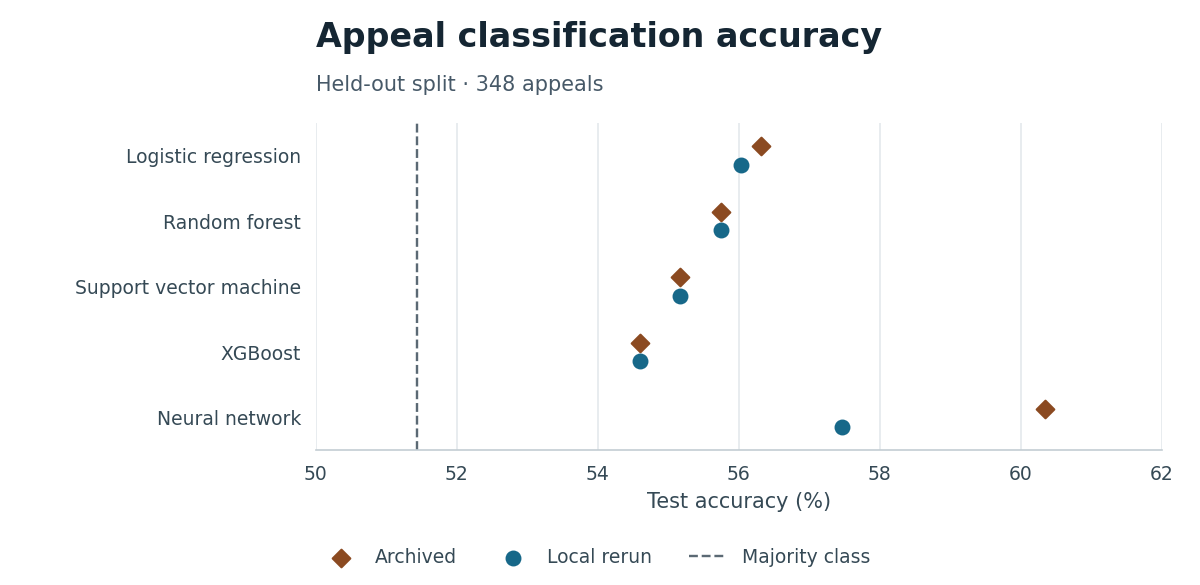

| Classifier | Archived accuracy | Local rerun |
| --- | ---: | ---: |
| Logistic regression | 56.32% | 56.03% |
| Random forest | 55.75% | 55.75% |
| Support vector machine | 55.17% | 55.17% |
| XGBoost | 54.60% | 54.60% |
| Neural network | 60.34% | 57.47% |

Predicting the majority class on the 348-appeal test split gives 51.44% accuracy. The neural network was trained without a fixed seed. TF–IDF was fitted before splitting the data, so these scores are exploratory.

In [ ]:
from pathlib import Path
import os

# Jupyter may start the kernel in the notebook directory or in the repository root.
repo_root = Path.cwd()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent
DATA_DIR = Path(os.getenv("TWITCH_MODERATION_DATA") or repo_root / "data" / "private").expanduser()

import pandas as pd
import numpy as np
import plotly.express as px

import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer

## Dataset

In [ ]:
# Import the dataset

dataset = pd.read_excel(DATA_DIR / "appeals/requests.xlsx")
dataset['status'] = dataset['status'].map({'approved': 1, 'denied': 0})

## Preprocessing 

In [ ]:
# Install the NLTK resources listed in the README before running this notebook.

# Function for text preprocessing
def preprocess_text(text):
    # Lowercasing
    text = text.lower()

    # Removing punctuation and special characters
    text = re.sub(r'[^\w\s]', '', text)

    # Removing numbers
    text = re.sub(r'\d+', '', text)

    # Tokenization
    tokens = word_tokenize(text)

    # Removing stopwords
    stop_words = set(stopwords.words('italian'))
    tokens = [word for word in tokens if word not in stop_words]

    # Stemming
    stemmer = PorterStemmer()
    tokens = [stemmer.stem(word) for word in tokens]

    # Lemmatization
    lemmatizer = WordNetLemmatizer()
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    # Joining tokens back into a single string
    preprocessed_text = ' '.join(tokens)

    return preprocessed_text

dataset['preprocessed_text'] = dataset['text'].apply(preprocess_text)

# Filter out texts with less than 6 words
#
data = dataset[dataset['preprocessed_text'].str.split().apply(len) > 5]


In [ ]:
def count_words(text):
    return len(text.split())


# Extract rows where 'status' is 'approved'
approved_data = data[data['status'] == 1]

# Calculate the total number of 'approved' available
total_approved_available = approved_data.shape[0]

# Calculate the proportions of 'approved' for each broadcaster_login
approved_counts = approved_data['broadcaster_login'].value_counts()
approved_proportions = approved_counts / approved_counts.sum()

# Calculate the number of 'denied' rows needed for each broadcaster_login based on 'approved' proportions
denied_counts = (approved_proportions * total_approved_available).round().astype(int)

# Adjust the total number of 'denied' rows if it does not match the total number of 'approved'
total_denied_calculated = denied_counts.sum()
if total_denied_calculated != total_approved_available:
    difference = total_approved_available - total_denied_calculated
    denied_counts[denied_counts.idxmax()] += difference

# Randomly sample 'denied' rows for each broadcaster_login based on the calculated counts
balanced_approved_denied_dataset = pd.DataFrame()
for broadcaster, needed in denied_counts.items():
    broadcaster_denied = data[(data['broadcaster_login'] == broadcaster) &
                                       (data['status'] == 0)]
    if len(broadcaster_denied) >= needed:
        sampled_denied = broadcaster_denied.sample(n=needed, random_state=1)
    else:
        sampled_denied = broadcaster_denied.sample(n=needed, replace=True, random_state=1)  # Use replace if not enough rows
    # Append both 'approved' and 'denied' rows for the broadcaster
    balanced_approved_denied_dataset = pd.concat([balanced_approved_denied_dataset, sampled_denied, 
                                                  approved_data[approved_data['broadcaster_login'] == broadcaster]])

# Remove the 'broadcaster_login' column from the final DataFrame
dataset = balanced_approved_denied_dataset.drop(columns='broadcaster_login')


In [ ]:
category_counts = dataset['status'].value_counts().reset_index()
category_counts.columns = ['status', 'Counts']

# Create a pie chart
fig = px.pie(category_counts, values='Counts', names='status', title='Distribution of Categories')

# Show the plot
fig.show()

## Visualization of word frequency distribution

In [ ]:
approved_texts = dataset[dataset['status']==1]['preprocessed_text']
denied_texts = dataset[dataset['status']==0]['preprocessed_text']

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# Compute word frequencies for approved and denied texts separately
approved_word_counts = Counter(word for doc in approved_texts for word in doc.split())
denied_word_counts = Counter(word for doc in denied_texts for word in doc.split())

# Get all unique words
all_words = set(list(approved_word_counts.keys()) + list(denied_word_counts.keys()))

# Initialize lists to store frequencies for approved and denied texts
approved_frequencies = []
denied_frequencies = []

# Loop through all unique words
for word in all_words:
    approved_frequencies.append(approved_word_counts.get(word, 0))
    denied_frequencies.append(denied_word_counts.get(word, 0))

# Find the count of the most frequent word
max_frequency_approved = max(approved_frequencies)
max_frequency_denied = max(denied_frequencies)

# Normalize the frequencies by the maximum frequency
normalized_approved_frequencies = [freq / max_frequency_approved for freq in approved_frequencies]
normalized_denied_frequencies = [freq / max_frequency_denied for freq in denied_frequencies]

# Sort by frequency for better visualization
sorted_indices_approved = sorted(range(len(normalized_approved_frequencies)), key=lambda i: normalized_approved_frequencies[i], reverse=True)
sorted_indices_denied = sorted(range(len(normalized_denied_frequencies)), key=lambda i: normalized_denied_frequencies[i], reverse=True)

sorted_words_approved = [list(all_words)[i] for i in sorted_indices_approved]
sorted_frequencies_approved = [normalized_approved_frequencies[i] for i in sorted_indices_approved]

sorted_words_denied = [list(all_words)[i] for i in sorted_indices_denied]
sorted_frequencies_denied = [normalized_denied_frequencies[i] for i in sorted_indices_denied]

# Set the width of the bars
bar_width = 0.35

# Set the positions of the bars on the x-axis, excluding the 8th word
r1 = np.arange(len(sorted_words_approved[:20]))
r2 = [x + bar_width for x in r1]

# Plot the frequency distributions
plt.figure(figsize=(12, 6))

# Plot denied word frequencies
plt.bar(r2, sorted_frequencies_denied[:20], color='violet', width=bar_width, label='Denied')

# Plot approved word frequencies
plt.bar(r1, sorted_frequencies_approved[:20], color='royalblue', width=bar_width, label='Approved')

plt.title('Normalized Word Frequency Distribution in Approved and Denied Requests')
plt.xlabel('Words')
plt.ylabel('Normalized Frequency')
plt.xticks([r + bar_width/2 for r in range(len(r1))], sorted_words_approved[:20] , rotation=45, ha='right')
plt.legend()
plt.tight_layout()

plt.savefig(DATA_DIR / "appeals/distribution.jpg", dpi = 500)
plt.show()



## Vectorization

In [ ]:
preprocessed_corpus = dataset['preprocessed_text'].to_list()

# Obtain TF-IDF Vectorizations for our texts to be input for our models
from sklearn.feature_extraction.text import TfidfVectorizer

# List of sentences
sentences = preprocessed_corpus

# Create a TfidfVectorizer
tfidf_vectorizer = TfidfVectorizer(max_features = 128, ngram_range=(1,3))

# Fit and transform the sentences
tfidf_matrix = tfidf_vectorizer.fit_transform(sentences)

# Convert the sparse matrix to an array
tfidf_array = tfidf_matrix.toarray()

# Get the feature names (words)
feature_names = tfidf_vectorizer.get_feature_names_out()

## Fit models

In [ ]:
import pickle

# Serialize the vectorizer for future use
with open(DATA_DIR / "appeals/tfidf_vectorizer.pkl", 'wb') as f:
    pickle.dump(tfidf_vectorizer, f)

In [ ]:
# Create our train/test, split
from sklearn.model_selection import train_test_split

target_labels = dataset['status'].tolist()
X_train, X_test, y_train, y_test = train_test_split(tfidf_array, target_labels, test_size=0.2, random_state=42)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Train a logistic regression classifier
classifier = LogisticRegression(max_iter=1000)  
classifier.fit(X_train, y_train)

# Predict on the test set
y_pred = classifier.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print("Logistic regression accuracy:", accuracy)

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='d', cbar=False)
plt.title('Confusion Matrix - Logistic Regression Classifier')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Train a Random Forest classifier
classifier_rf = RandomForestClassifier(n_estimators=100, random_state=42)  # You can adjust hyperparameters as needed
classifier_rf.fit(X_train, y_train)

# Predict on the test set
y_pred_rf = classifier_rf.predict(X_test)

# Evaluate the model
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print("Random Forest accuracy:", accuracy_rf)

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='d', cbar=False)
plt.title('Confusion Matrix - Logistic Regression Classifier')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()


In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Train an SVM classifier
svm_classifier = SVC(kernel='linear') 
svm_classifier.fit(X_train, y_train)

# Predict on the test set
y_pred = svm_classifier.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print("SVM Accuracy:", accuracy)

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='d', cbar=False)
plt.title('Confusion Matrix - Logistic Regression Classifier')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

In [ ]:
import xgboost as xgb

# Define the XGBoost model
model = xgb.XGBClassifier()

# Train the model
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='d', cbar=False)
plt.title('Confusion Matrix - Logistic Regression Classifier')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Prepare the labels for the dataset
# Assuming y_train and y_test are already defined somewhere in your code
train_y = torch.tensor(y_train, dtype=torch.long)
train_y = F.one_hot(train_y).float()  # Converting labels to one-hot encoding

test_y = torch.tensor(y_test, dtype=torch.long)
test_y = F.one_hot(test_y).float()

# Prepare the data loaders
train_dataset = TensorDataset(torch.tensor(X_train).float(), train_y)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

test_dataset = TensorDataset(torch.tensor(X_test).float(), test_y)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

# Define the Neural Network
class NeuralNet(nn.Module):
    def __init__(self):
        super(NeuralNet, self).__init__()
        self.fc1 = nn.Linear(X_train.shape[1], 32)  # Adjust the input size appropriately
        self.dropout = nn.Dropout(0.05)
        self.fc2 = nn.Linear(32, 2)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Initialize the model
model = NeuralNet()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

# Train the model
model.train()
for epoch in range(5):  # Loop over the dataset multiple times
    running_loss = 0.0
    for inputs, labels in train_loader:
        optimizer.zero_grad()

        # Forward + backward + optimize
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f'Epoch {epoch + 1}, Loss: {running_loss / len(train_loader)}')

# Evaluate the model
model.eval()
test_loss = 0
correct = 0
total = 0
with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        test_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        _, true_labels = torch.max(labels.data, 1)
        total += labels.size(0)
        correct += (predicted == true_labels).sum().item()

print(f'Test loss: {test_loss / len(test_loader)}, Test accuracy: {100 * correct / total}')


## 3D PCA Visualization

In [ ]:
import plotly.express as px
import plotly.graph_objects as go
from sklearn.decomposition import PCA

# PCA with 3 components
pca = PCA(n_components=3)
X_pca = pca.fit_transform(tfidf_array)  # Ensure tfidf_array is predefined

# Map target labels to labels
labels = ['Approved' if label == 1 else 'Denied' for label in target_labels]

# Create a DataFrame for Plotly
df = pd.DataFrame({
    'PC 1': X_pca[:, 0],
    'PC 2': X_pca[:, 1],
    'PC 3': X_pca[:, 2],
    'Label': labels
})

# Plotting using Plotly Express
fig = px.scatter_3d(df, x='PC 1', y='PC 2', z='PC 3', color='Label', opacity=0.5, labels={'Label': 'Approval Status'})
fig.update_layout(
    title='3D PCA Plot of Text Data',
    legend_title_text='Approval Status',
    updatemenus=[
        dict(
            type="buttons",
            direction="right",
            x=0.57,
            y=1.2,
            buttons=list([
                dict(label="All",
                     method="update",
                     args=[{"visible": [True, True]},
                           {"title": "3D PCA Plot of Text Data: All"}]),
                dict(label="Approved",
                     method="update",
                     args=[{"visible": [True, False]},
                           {"title": "3D PCA Plot of Text Data: Approved"}]),
                dict(label="Denied",
                     method="update",
                     args=[{"visible": [False, True]},
                           {"title": "3D PCA Plot of Text Data: Denied"}])
            ]),
        )
    ]
)

fig.show()
